In [1]:
!conda env create --name q2-fungal-traits-moshpit-2026.10 --file https://raw.githubusercontent.com/bokulich-lab/q2-fungal-traits/refs/heads/main/environment-files/q2-fungal-traits-rachis-moshpit-2026.10.yml
!conda run --no-capture-output -n q2-fungal-traits-moshpit-2026.10 pip install "q2-fungal-traits@git+https://github.com/bokulich-lab/q2-fungal-traits.git"
!conda run --no-capture-output -n q2-fungal-traits-moshpit-2026.10 qiime dev refresh-cache

Error loading anaconda-anon-usage: module 'conda.cli.install' has no attribute 'check_prefix'
Retrieving notices: done
Channels:
 - https://packages.qiime2.org/qiime2/2026.10/moshpit/released
 - conda-forge
 - bioconda
 - defaults
Platform: linux-64
Solving environment: done

## Package Plan ##

  environment location: /opt/conda/envs/q2-fungal-traits-moshpit-2026.10

  added / updated specs:
    - pip
    - rachis-moshpit


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    libpython-3.12.15          |ha57cdbe_2_cpython         8.4 MB  conda-forge
    python-3.12.14             |h8ab3286_1_cpython        30.1 MB  conda-forge
    ------------------------------------------------------------
                                           Total:        38.5 MB

The following NEW packages will be INSTALLED:

  _openmp_mutex      conda-forge/linux-64::_openmp_mutex-4.5-8_kmp_llvm 
  _python_abi3_sup

In [2]:
!conda run --no-capture-output -n q2-fungal-traits-moshpit-2026.10 qiime fungal-traits annotate --help

Usage: qiime fungal-traits annotate [OPTIONS]

  Annotate taxonomy data with fungal lifestyle traits and spore volume
  metadata. Fungal trait annotation is performed when both genus and phylum
  are present, because the trait table is matched by genus and then filtered
  so only rows with the same phylum are retained. Spore volume annotation is
  performed when kingdom is present together with at least one of species,
  genus, or family. Spore matching is done in a simple fallback order: first
  try an exact species match, if that is not available try genus, and if that
  is still not available try family. Species matches use the direct spore
  volume from the source table. Genus and family matches summarize the
  available values for that rank with a geometric mean and record which rank
  was used, so it is clear whether a value came from a species, genus, or
  family-level match.

Inputs:
  --i-taxonomy ARTIFACT FeatureData[Taxonomy]
                         Fungal taxonomy.        

In [4]:
import os

ft_env   = "q2-fungal-traits-moshpit-2026.10"
in_dir_1 = "/home/jovyan/FunGut/data/processed"
in_dir_2 = "/home/jovyan/FunGut/data/processed_ignored"
out_dir_1  = "/home/jovyan/FunGut/data/processed/Fungal_Annotation"
out_dir_2  = "/home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation"

os.makedirs(out_dir_1, exist_ok=True)
os.makedirs(out_dir_2, exist_ok=True)

In [11]:
!conda run --no-capture-output -n $ft_env \
  qiime fungal-traits annotate \
  --i-taxonomy "$in_dir_2/03_taxonomy/taxonomy.qza" \
  --o-fungal-traits "$out_dir_2/fungal_traits.qza"

Saved ImmutableMetadata to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/fungal_traits.qza


In [12]:
!conda run --no-capture-output -n $ft_env \
  qiime metadata tabulate \
  --m-input-file "$out_dir_2/fungal_traits.qza" \
  --o-visualization "$out_dir_1/fungal_traits.qzv"

Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/fungal_traits.qzv


In [13]:
!conda run --no-capture-output -n $ft_env \
  qiime tools export \
  --input-path "$out_dir_2/fungal_traits.qza" \
  --output-path "$out_dir_2/fungal_traits_tsv"

Exported /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/fungal_traits.qza as ImmutableMetadataDirectoryFormat to directory /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/fungal_traits_tsv


In [14]:
import pandas as pd

traits = pd.read_csv(f"{out_dir_2}/fungal_traits_tsv/metadata.tsv", sep="\t", index_col=0)
traits = traits[~traits.index.astype(str).str.startswith("#")]

print("Features in total:", len(traits))
for col in ["fruitbody_type_template", "primary_lifestyle", "growth_form_template"]:
    print("\n=====", col)
    print(traits[col].value_counts(dropna=False))

Features in total: 681

===== fruitbody_type_template
fruitbody_type_template
none                                             317
NaN                                              293
perithecium_(hymenium_hidden,_narrow_opening)     35
agaricoid                                         11
cleistothecium_(closed,_spherical)                 7
polyporoid                                         5
corticioid                                         5
apothecium_(hymenium_on_surface)                   4
other                                              2
clavarioid                                         1
cyphelloid                                         1
Name: count, dtype: int64

===== primary_lifestyle
primary_lifestyle
NaN                       190
nectar/tap_saprotroph     177
unspecified_saprotroph     93
litter_saprotroph          54
soil_saprotroph            43
animal_parasite            40
plant_pathogen             37
wood_saprotroph            26
dung_saprotroph             6


### Take rarified table from Alpha Diversity here and remove fungi that likely come from food instead of the gut microbiome and run Alpha Diversity again and compare with results from Alpha Diversity before

#### First see which ASVs would be removed, if we remove fungi with macro fruitbodies and fungi with symbiont lifestyle

In [5]:
import pandas as pd

traits = pd.read_csv(f"{out_dir_2}/fungal_traits_tsv/metadata.tsv", sep="\t", index_col=0)
traits = traits[~traits.index.astype(str).str.startswith("#")]

macro_fruitbodies = ["agaricoid", "apothecium_(hymenium_on_surface)", "clathroid", "clavarioid",
                     "corticioid", "cyphelloid", "gasteroid", "gasteroid-hypogeous",
                     "hysterothecium_(opening_slit-like)", "mazaedium_(pushpin-like)",
                     "phalloid", "polyporoid", "tremelloid"]
symbiont_lifestyles = ["arbuscular_mycorrhizal", "ectomycorrhizal", "lichenized"]

to_remove = traits[traits["fruitbody_type_template"].isin(macro_fruitbodies) |
                   traits["primary_lifestyle"].isin(symbiont_lifestyles)]

print(len(to_remove), "ASVs would be removed:\n")
print(to_remove[["fungal_traits_genus", "primary_lifestyle", "fruitbody_type_template"]]
      .sort_values("fungal_traits_genus").to_string())

27 ASVs would be removed:

                                 fungal_traits_genus     primary_lifestyle           fruitbody_type_template
feature-id                                                                                                  
1d0faf5fd180a8fdb2bf814609069c4a            Agaricus       soil_saprotroph                         agaricoid
5757289212ca62c7993b7326306cf2fc            Agaricus       soil_saprotroph                         agaricoid
f53ae2c94bc43d691c2163949e5f9037            Agaricus       soil_saprotroph                         agaricoid
e8a1ef518e60a69d7787ef5547bfedec          Ascodesmis       dung_saprotroph  apothecium_(hymenium_on_surface)
be0cce11d75e137250933ce2372b010c             Boletus       ectomycorrhizal                         agaricoid
e36356de3a67a2e907d6c5f3fdfd4536         Coprinellus       soil_saprotroph                         agaricoid
f1866a630d97457c5cb58f8e42f82343          Coronicium     litter_saprotroph                        cor

#### Remove those

In [6]:
!qiime feature-table filter-features \
  --i-table "$in_dir_2/06_diversity/core_metrics/rarefied_table.qza" \
  --m-metadata-file "$out_dir_2/fungal_traits_tsv/metadata.tsv" \
  --p-where "[fruitbody_type_template] IN ('agaricoid','apothecium_(hymenium_on_surface)','clathroid','clavarioid','corticioid','cyphelloid','gasteroid','gasteroid-hypogeous','hysterothecium_(opening_slit-like)','mazaedium_(pushpin-like)','phalloid','polyporoid','tremelloid') OR [primary_lifestyle] IN ('arbuscular_mycorrhizal','ectomycorrhizal','lichenized')" \
  --p-exclude-ids \
  --o-filtered-table "$out_dir_2/rarefied_table_wo_nongutfungi.qza"

Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/rarefied_table_wo_nongutfungi.qza


In [7]:
!qiime diversity alpha --i-table "$out_dir_2/rarefied_table_wo_nongutfungi.qza" --p-metric observed_features --o-alpha-diversity "$out_dir_2/observed_features_vector.qza"
!qiime diversity alpha --i-table "$out_dir_2/rarefied_table_wo_nongutfungi.qza" --p-metric shannon           --o-alpha-diversity "$out_dir_2/shannon_vector.qza"
!qiime diversity alpha --i-table "$out_dir_2/rarefied_table_wo_nongutfungi.qza" --p-metric pielou_e          --o-alpha-diversity "$out_dir_2/evenness_vector.qza"

Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/observed_features_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/shannon_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/evenness_vector.qza


In [10]:
import pandas as pd, zipfile

def load_alpha(path):
    with zipfile.ZipFile(path) as z:
        inner = [n for n in z.namelist() if n.endswith("data/alpha-diversity.tsv")][0]
        return pd.read_csv(z.open(inner), sep="\t", index_col=0).iloc[:, 0]

files = {"Richness": "observed_features_vector.qza",
         "Shannon":  "shannon_vector.qza",
         "Evenness": "evenness_vector.qza"}

parts = []
for metric, fname in files.items():
    before = load_alpha(f"{in_dir_2}/06_diversity/core_metrics/{fname}")     # unfiltered
    after  = load_alpha(f"{out_dir_2}/{fname}")   # without non-intrinsic fungi
    d = pd.concat({"before": before, "after": after}, axis=1).dropna()
    d["metric"] = metric
    parts.append(d)
alpha = pd.concat(parts)

alpha.groupby("metric")[["before", "after"]].median()

,before,after
metric,,
Evenness,0.196522,0.200104
Richness,12.000000,12.000000
Shannon,0.713753,0.712898


In [11]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

res = []
for metric, d in alpha.groupby("metric"):
    stat, p = wilcoxon(d["before"], d["after"])
    res.append({"metric": metric,
                "n_samples": len(d),
                "samples_changed": int((d["before"] != d["after"]).sum()),
                "median_before": d["before"].median(),
                "median_after": d["after"].median(),
                "W": stat, "p": p})
res = pd.DataFrame(res)
res["p_BH"] = multipletests(res["p"], method="fdr_bh")[1]
res

,metric,n_samples,samples_changed,median_before,median_after,W,p,p_BH
0,Evenness,150,34,0.196522,0.200104,70.0,1.004687e-04,1.004687e-04
1,Richness,150,34,12.000000,12.000000,0.0,9.975390e-08,2.992617e-07
2,Shannon,150,34,0.713753,0.712898,0.0,3.652833e-07,5.479250e-07


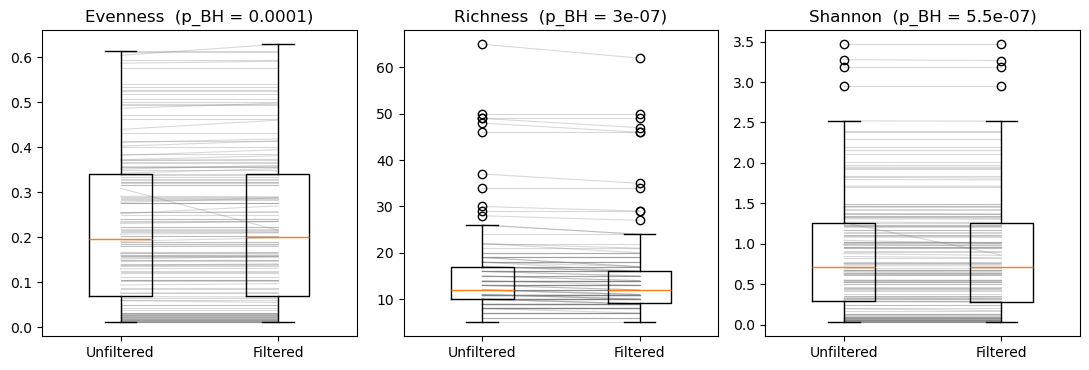

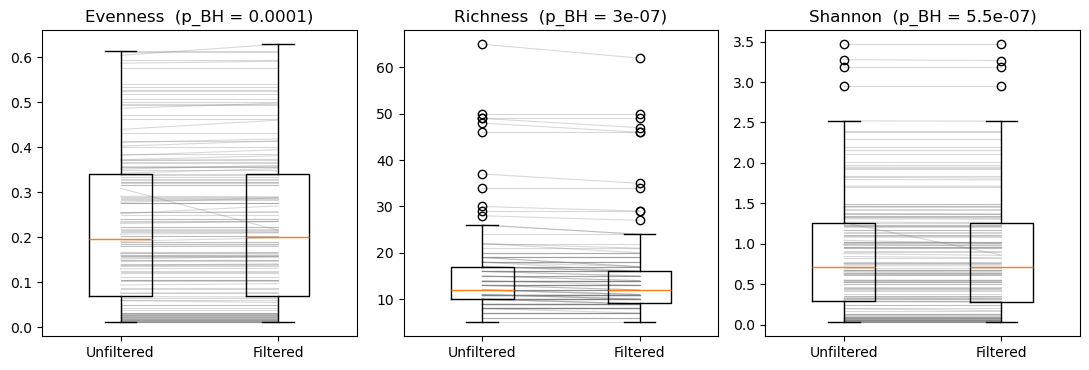

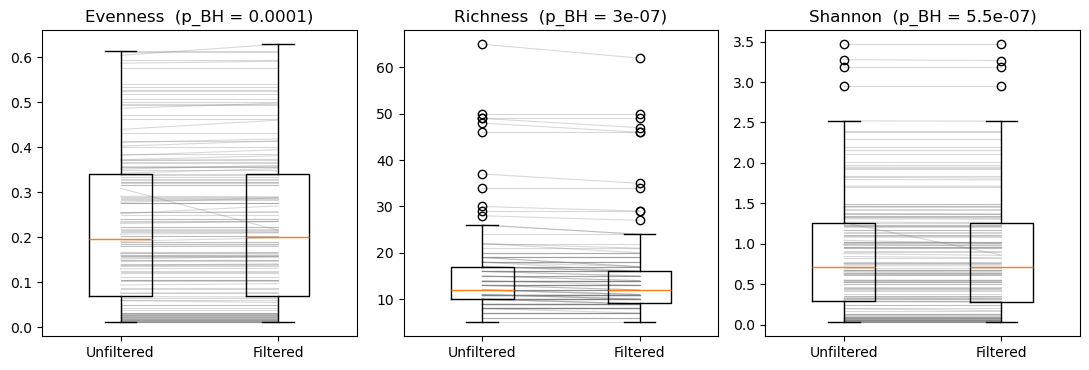

In [14]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (metric, d) in zip(axes, alpha.groupby("metric")):
    for _, r in d.iterrows():
        ax.plot([0, 1], [r["before"], r["after"]], color="grey", alpha=0.3, lw=0.8)
    ax.boxplot([d["before"], d["after"]], positions=[0, 1], widths=0.4)
    p_adj = res.loc[res["metric"] == metric, "p_BH"].values[0]
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Unfiltered", "Filtered"])
    ax.set_title(f"{metric}  (p_BH = {p_adj:.2g})")
plt.tight_layout()
plt.savefig(f"{out_dir_1}/alpha_before_after.png", dpi=300)
plt.show()

#### Only look at 34 affected samples that were changed by filtering:

In [15]:
changed = alpha[alpha["before"] != alpha["after"]].copy()
changed["diff"] = changed["after"] - changed["before"]
changed["pct_change"] = changed["diff"] / changed["before"] * 100
changed.groupby("metric")[["diff", "pct_change"]].agg(["median", "min", "max"])

diff                     pct_change                     
            median       min       max     median        min       max
metric                                                                
Evenness  0.002700 -0.093344  0.024611   1.956766 -30.256942  6.732980
Richness -1.000000 -3.000000 -1.000000  -7.692308 -12.500000 -3.333333
Shannon  -0.003516 -0.400358 -0.000841  -0.417906 -31.749292 -0.043242

#### Non-intrinsic fungi (macrofungi and ectomycorrhizal taxa) were detected in 34 of 150 samples (23%). Removing them significantly reduced richness and Shannon diversity and slightly increased evenness (paired Wilcoxon signed-rank tests, BH-adjusted p < 0.001). However, the effect was small (median change in affected samples: richness −1 ASVs [−7.7%]), and median values across all samples were essentially unchanged. Alpha diversity estimates are therefore robust to the presence of these likely diet-derived fungi.

In [18]:
metadata = "/home/jovyan/FunGut/data/raw/Final_metadata_with_GHSL.tsv"

In [20]:
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

meta = pd.read_csv(metadata, sep="\t", index_col=0, dtype=str)
meta = meta[~meta.index.astype(str).str.startswith("#")]      # removes QIIME info rows

shannon = alpha[alpha["metric"] == "Shannon"].copy()           # Shannon only
shannon.index = shannon.index.astype(str)                      # so sample IDs match

# columns that look like groups: 2 to 10 different values
group_cols = [c for c in meta.columns if 2 <= meta[c].nunique(dropna=True) <= 10]
print("Tested columns:", group_cols)

rows = []
for col in group_cols:
    d = shannon.join(meta[col]).dropna(subset=[col])
    sizes = d[col].value_counts()
    d = d[d[col].isin(sizes[sizes >= 3].index)]                # only groups with at least 3 samples
    if d[col].nunique() < 2:
        continue
    for value_col, version in [("before", "unfiltered"), ("after", "filtered")]:
        groups = [g[value_col].values for _, g in d.groupby(col)]
        try:
            H, p = kruskal(*groups)
        except ValueError:                                     # e.g. all values identical
            H, p = float("nan"), float("nan")
        rows.append({"column": col, "version": version,
                     "n_groups": d[col].nunique(), "n_samples": len(d), "H": H, "p": p})

kw = pd.DataFrame(rows)
kw["p_BH"] = kw.groupby("version")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])

table = kw.pivot_table(index="column", columns="version", values="p_BH")
table["same_conclusion"] = (table["unfiltered"] < 0.05) == (table["filtered"] < 0.05)
table.sort_values("unfiltered")

Tested columns: ['country_sample', 'sex_sample', 'diet_type_sample', 'ibd_sample', 'gluten_sample', 'Settlement_Type']


version,filtered,unfiltered,same_conclusion
column,,,
diet_type_sample,0.399960,0.398971,True
gluten_sample,0.414768,0.430583,True
sex_sample,0.414768,0.430583,True
country_sample,0.429753,0.441775,True
ibd_sample,0.429753,0.441775,True
Settlement_Type,0.784448,0.771402,True


In [22]:
%%bash -s "$cm_dir" "$filt_dir" "$vis_dir" "$metadata"
cm_dir=$1; filt_dir=$2; vis_dir=$3; metadata=$4

for metric in shannon; do
    qiime diversity alpha-group-significance \
    --i-alpha-diversity $out_dir_2/${metric}_vector.qza \
    --m-metadata-file "/home/jovyan/FunGut/data/raw/Final_metadata_with_GHSL.tsv" \
    --o-visualization $out_dir_1/${metric}_group_significance_filtered.qzv

    qiime diversity alpha-correlation \
    --i-alpha-diversity $out_dir_2/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $out_dir_1/${metric}_correlation_filtered.qzv
done

Usage: qiime diversity alpha-group-significance [OPTIONS]

  Visually and statistically compare groups of alpha diversity values.

Inputs:
  --i-alpha-diversity ARTIFACT SampleData[AlphaDiversity]
                         Vector of alpha diversity values by sample.
                                                                    [required]
Parameters:
  --m-metadata-file METADATA...
    (multiple            The sample metadata.
     arguments will be   
     merged)                                                        [required]
Outputs:
  --o-visualization VISUALIZATION
                                                                    [required]
Miscellaneous:
  --output-dir PATH      Output unspecified results to a directory
  --verbose / --quiet    Display verbose output to stdout and/or stderr
                         during execution of this action. Or silence output if
                         execution is successful (silence is golden).
  --example-data PATH    Write exam

CalledProcessError: Command 'b'cm_dir=$1; filt_dir=$2; vis_dir=$3; metadata=$4\n\nfor metric in shannon; do\n    qiime diversity alpha-group-significance \\\n    --i-alpha-diversity $out_dir_2/${metric}_vector.qza \\\n    --m-metadata-file "/home/jovyan/FunGut/data/raw/Final_metadata_with_GHSL.tsv" \\\n    --o-visualization $out_dir_1/${metric}_group_significance_filtered.qzv\n\n    qiime diversity alpha-correlation \\\n    --i-alpha-diversity $out_dir_2/${metric}_vector.qza \\\n    --m-metadata-file $metadata \\\n    --o-visualization $out_dir_1/${metric}_correlation_filtered.qzv\ndone\n'' returned non-zero exit status 1.